<a href="https://colab.research.google.com/github/Soju-004/Thyroid-Disease_Team-Data-Prerprocessing-Project/blob/Complete-Data-Preprocessing/Class_Imbalance_and_Feature_Selection_Soju_Jacob_Sony.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from imblearn.over_sampling import SMOTE

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
file_path = "/content/drive/MyDrive/ICT-Project-Dataset/thyroidDF.csv"
df = pd.read_csv(file_path)

#EDA and Visualization


In [5]:
df.head()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
0,29,F,f,f,f,f,f,f,f,t,...,NaN,f,NaN,f,NaN,f,NaN,other,-,840801013
1,29,F,f,f,f,f,f,f,f,f,...,128.0,f,NaN,f,NaN,f,NaN,other,-,840801014
2,41,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,11.0,other,-,840801042
3,36,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,26.0,other,-,840803046
4,32,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,36.0,other,S,840803047


In [6]:
pd.set_option("display.max_columns",None)

In [7]:
df.tail()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH_measured,TSH,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
9167,56,M,f,f,f,f,f,f,f,f,t,f,f,f,f,f,f,NaN,f,NaN,t,64.0,t,0.83,t,77.0,f,NaN,SVI,-,870119022
9168,22,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,t,91.0,t,0.92,t,99.0,f,NaN,SVI,-,870119023
9169,69,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,t,113.0,t,1.27,t,89.0,f,NaN,SVI,I,870119025
9170,47,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,t,75.0,t,0.85,t,88.0,f,NaN,other,-,870119027
9171,31,M,f,f,f,f,f,f,f,t,f,f,f,f,f,f,f,NaN,f,NaN,t,66.0,t,1.02,t,65.0,f,NaN,other,-,870119035


In [8]:
df.sample()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH_measured,TSH,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
6877,49,F,f,f,f,f,f,t,f,f,f,f,f,f,f,f,t,3.7,t,2.0,t,53.0,t,0.71,t,75.0,f,NaN,other,-,860711021


In [9]:
df.describe()

,age,TSH,T3,TT4,T4U,FTI,TBG,patient_id
count,9172.000000,8330.000000,6568.000000,8730.000000,8363.000000,8370.000000,349.000000,9.172000e+03
mean,73.555822,5.218403,1.970629,108.700305,0.976056,113.640746,29.870057,8.529473e+08
std,1183.976718,24.184006,0.887579,37.522670,0.200360,41.551650,21.080504,7.581969e+06
min,1.000000,0.005000,0.050000,2.000000,0.170000,1.400000,0.100000,8.408010e+08
25%,37.000000,0.460000,1.500000,87.000000,0.860000,93.000000,21.000000,8.504090e+08
50%,55.000000,1.400000,1.900000,104.000000,0.960000,109.000000,26.000000,8.510040e+08
75%,68.000000,2.700000,2.300000,126.000000,1.065000,128.000000,31.000000,8.607110e+08
max,65526.000000,530.000000,18.000000,600.000000,2.330000,881.000000,200.000000,8.701190e+08


In [10]:
df.shape

(9172, 31)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9172 entries, 0 to 9171
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  9172 non-null   int64  
 1   sex                  8865 non-null   object 
 2   on_thyroxine         9172 non-null   object 
 3   query_on_thyroxine   9172 non-null   object 
 4   on_antithyroid_meds  9172 non-null   object 
 5   sick                 9172 non-null   object 
 6   pregnant             9172 non-null   object 
 7   thyroid_surgery      9172 non-null   object 
 8   I131_treatment       9172 non-null   object 
 9   query_hypothyroid    9172 non-null   object 
 10  query_hyperthyroid   9172 non-null   object 
 11  lithium              9172 non-null   object 
 12  goitre               9172 non-null   object 
 13  tumor                9172 non-null   object 
 14  hypopituitary        9172 non-null   object 
 15  psych                9172 non-null   o

In [12]:
df.dtypes

,0
age,int64
sex,object
on_thyroxine,object
query_on_thyroxine,object
on_antithyroid_meds,object
sick,object
pregnant,object
thyroid_surgery,object
I131_treatment,object
query_hypothyroid,object


In [13]:
df.columns

Index(['age', 'sex', 'on_thyroxine', 'query_on_thyroxine',
       'on_antithyroid_meds', 'sick', 'pregnant', 'thyroid_surgery',
       'I131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium',
       'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH_measured', 'TSH',
       'T3_measured', 'T3', 'TT4_measured', 'TT4', 'T4U_measured', 'T4U',
       'FTI_measured', 'FTI', 'TBG_measured', 'TBG', 'referral_source',
       'target', 'patient_id'],
      dtype='object')

In [14]:
df['target'].value_counts()

,count
target,
-,6771
K,436
G,359
I,346
F,233
R,196
A,147
L,115
M,111


In [15]:
df.isna().sum()

,0
age,0
sex,307
on_thyroxine,0
query_on_thyroxine,0
on_antithyroid_meds,0
sick,0
pregnant,0
thyroid_surgery,0
I131_treatment,0
query_hypothyroid,0


In [16]:
(df.isna().sum() / len(df)) * 100

,0
age,0.000000
sex,3.347143
on_thyroxine,0.000000
query_on_thyroxine,0.000000
on_antithyroid_meds,0.000000
sick,0.000000
pregnant,0.000000
thyroid_surgery,0.000000
I131_treatment,0.000000
query_hypothyroid,0.000000


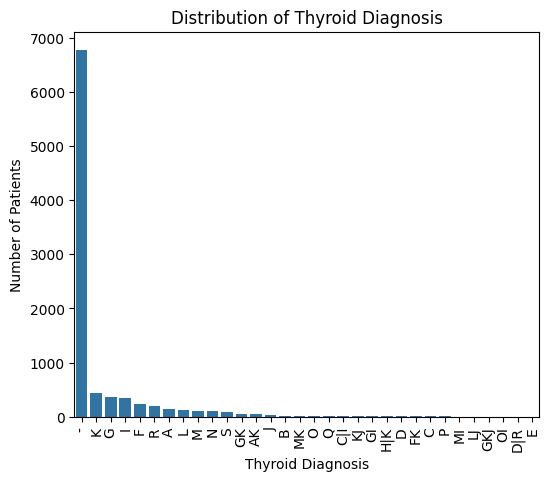

In [17]:
# Before removing null values
plt.figure(figsize=(6, 5))

sns.countplot(
    data=df,
    x='target',
    order=df['target'].value_counts().index
)

plt.title('Distribution of Thyroid Diagnosis')
plt.xlabel('Thyroid Diagnosis')
plt.ylabel('Number of Patients')
plt.xticks(rotation=90)

plt.show()

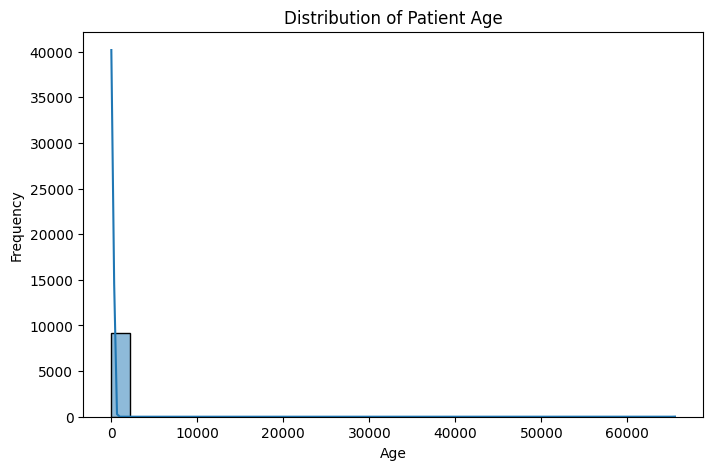

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title('Distribution of Patient Age')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

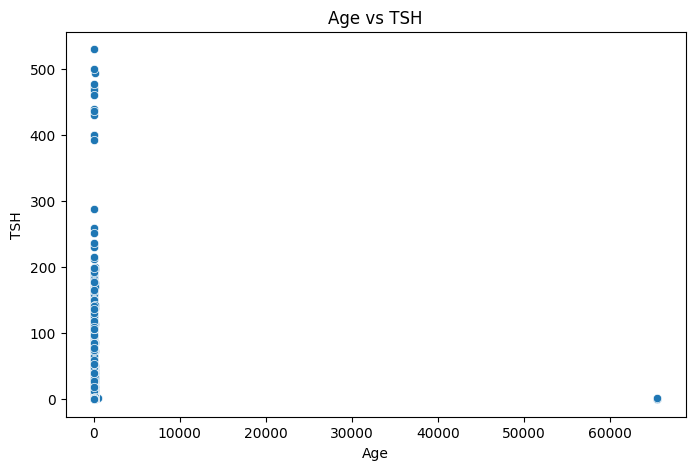

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='age', y='TSH')

plt.title('Age vs TSH')
plt.xlabel('Age')
plt.ylabel('TSH')

plt.show()

#Missing value Handling

**Before Data cleaning**

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df['target'].value_counts()

,count
target,
-,6771
K,436
G,359
I,346
F,233
R,196
A,147
L,115
M,111


In [22]:
df['referral_source'].value_counts()

,count
referral_source,
other,5493
SVI,2394
SVHC,956
STMW,255
SVHD,71
WEST,3


In [23]:
df['sex'].value_counts()

,count
sex,
F,6073
M,2792


In [24]:
df.isna().sum()

,0
age,0
sex,307
on_thyroxine,0
query_on_thyroxine,0
on_antithyroid_meds,0
sick,0
pregnant,0
thyroid_surgery,0
I131_treatment,0
query_hypothyroid,0


In [25]:
df.isna().sum()/df.shape[0]*100

,0
age,0.000000
sex,3.347143
on_thyroxine,0.000000
query_on_thyroxine,0.000000
on_antithyroid_meds,0.000000
sick,0.000000
pregnant,0.000000
thyroid_surgery,0.000000
I131_treatment,0.000000
query_hypothyroid,0.000000


**Data cleaning**

In [26]:
df.drop_duplicates(inplace=True)

In [27]:
class_counts = df["target"].value_counts()

valid_classes = class_counts[class_counts >= 2].index

df = df[df["target"].isin(valid_classes)]

In [28]:
df["target"] = (
    df["target"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.$", "", regex=True)
)

In [29]:
df["referral_source"] = df["referral_source"].str.strip()

In [30]:
df["sex"] = df["sex"].str.strip()

In [31]:
df = df.drop(columns=["TBG"])

In [32]:
df.replace("?", np.nan, inplace=True)

**after Datacleaning**

In [33]:
df.duplicated().sum()

np.int64(0)

In [34]:
df['target'].value_counts()

,count
target,
-,6771
K,436
G,359
I,346
F,233
R,196
A,147
L,115
M,111


In [35]:
df['referral_source'].value_counts()

,count
referral_source,
other,5489
SVI,2393
SVHC,956
STMW,255
SVHD,71
WEST,3


In [36]:
df['sex'].value_counts()

,count
sex,
F,6070
M,2790


In [37]:
df.isna().sum()/df.shape[0]*100

,0
age,0.000000
sex,3.348969
on_thyroxine,0.000000
query_on_thyroxine,0.000000
on_antithyroid_meds,0.000000
sick,0.000000
pregnant,0.000000
thyroid_surgery,0.000000
I131_treatment,0.000000
query_hypothyroid,0.000000


###splitting

In [38]:
X = df.drop("target", axis=1)
y = df["target"]

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (7333, 29)
Testing Data: (1834, 29)


In [40]:
num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

In [41]:
num_cols

Index(['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI', 'patient_id'], dtype='object')

In [42]:
cat_cols

Index(['sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_meds',
       'sick', 'pregnant', 'thyroid_surgery', 'I131_treatment',
       'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor',
       'hypopituitary', 'psych', 'TSH_measured', 'T3_measured', 'TT4_measured',
       'T4U_measured', 'FTI_measured', 'TBG_measured', 'referral_source'],
      dtype='object')

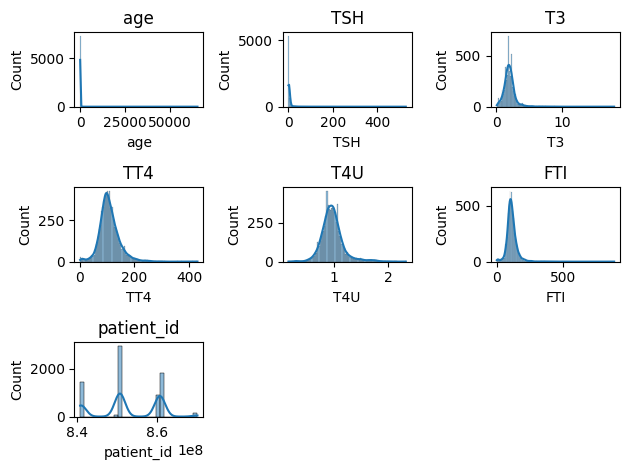

In [43]:
for i,col in enumerate(num_cols,1):
  plt.subplot(3,3,i)
  sns.histplot(X_train[col],kde=True)
  plt.title(col)
plt.tight_layout()
plt.show()

In [44]:
num_imputer=SimpleImputer(strategy='median')
X_train_num_imputer=num_imputer.set_output(transform='pandas').fit_transform(X_train[num_cols])
X_test_num_imputer=num_imputer.set_output(transform='pandas').transform(X_test[num_cols])

In [45]:
X_train_num_imputer

,age,TSH,T3,TT4,T4U,FTI,patient_id
5734,47.0,3.000,1.9,123.0,1.02,120.0,860211005.0
1223,26.0,5.500,1.9,124.0,1.02,121.0,841115019.0
5318,62.0,0.760,1.9,105.0,0.85,124.0,851203017.0
5388,29.0,1.100,3.8,161.0,1.74,93.0,851209016.0
5650,76.0,4.100,1.9,56.0,0.76,73.0,860206023.0
...,...,...,...,...,...,...,...
5144,25.0,1.400,2.2,113.0,1.08,105.0,851120078.0
3066,29.0,1.400,1.9,104.0,0.96,109.0,850605087.0
5901,39.0,7.100,1.9,106.0,0.94,114.0,860221056.0
4492,58.0,0.600,2.0,151.0,1.05,144.0,850927004.0


In [46]:
X_test_num_imputer

,age,TSH,T3,TT4,T4U,FTI,patient_id
5396,37.0,1.50,1.8,109.0,0.97,112.0,851209041.0
7778,87.0,3.30,1.1,64.0,0.55,116.0,860916063.0
5445,45.0,1.40,1.9,101.0,0.95,106.0,851211090.0
2075,38.0,0.20,2.0,78.0,0.85,92.0,850319004.0
7133,17.0,2.90,2.5,110.0,0.91,121.0,860731009.0
...,...,...,...,...,...,...,...
4442,14.0,3.60,1.2,103.0,0.88,118.0,850923029.0
2171,72.0,0.05,1.1,108.0,0.66,165.0,850327056.0
2373,24.0,0.15,2.7,116.0,0.82,143.0,850415027.0
8444,27.0,1.30,1.8,160.0,1.12,143.0,861111004.0


# Outlier Detection and Treatment- Abhimanyu S


##Identify numerical columns

In [47]:
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

outlier_cols = [col for col in num_cols if col != 'patient_id']

print("All numerical columns:", num_cols)
print("Columns selected for outlier analysis:", outlier_cols)


All numerical columns: ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI', 'patient_id']
Columns selected for outlier analysis: ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']


##Detect outliers using boxplots (Before treatment)

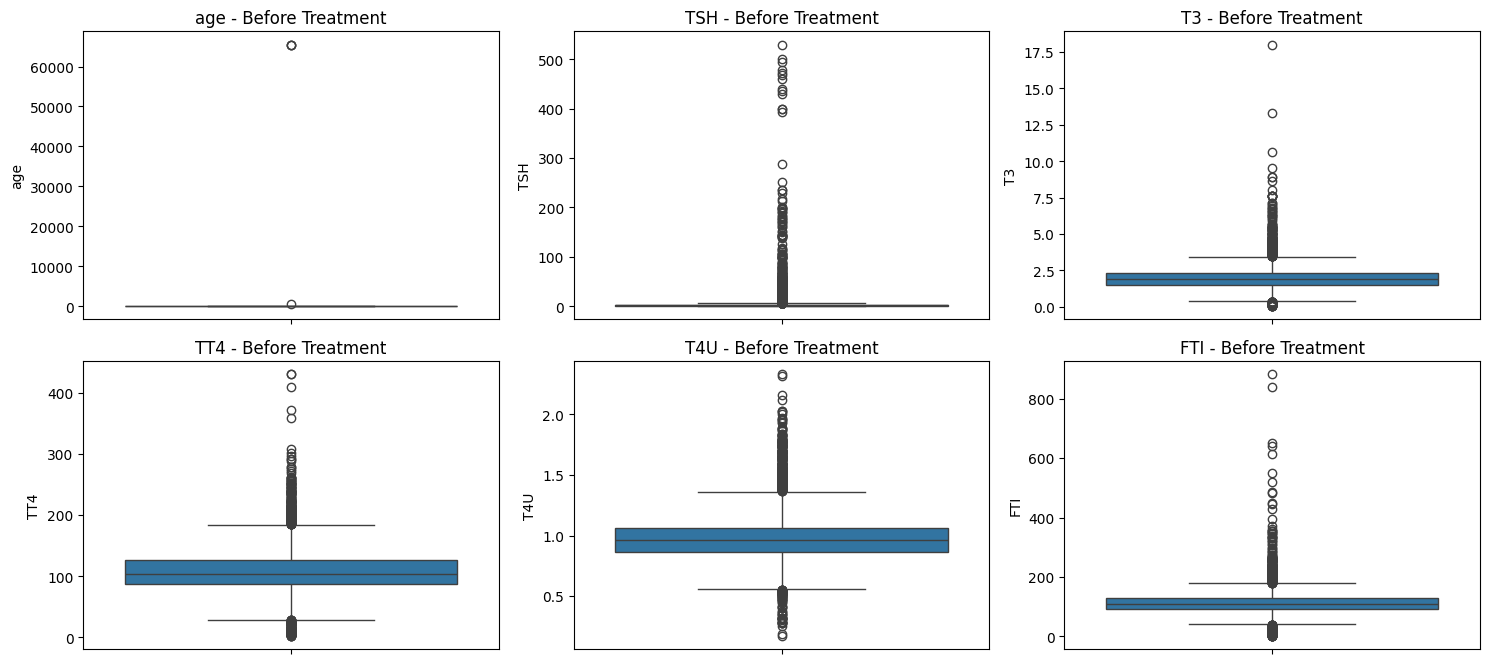

In [48]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(outlier_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=X_train[col])
    plt.title(f'{col} - Before Treatment')

plt.tight_layout()
plt.show()


Calculate IQR, lower bounds, upper bounds and outlier count

In [49]:
outlier_results = []

for col in outlier_cols:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    outlier_count = (
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    ).sum()

    outlier_percentage = (outlier_count / X_train[col].notna().sum()) * 100

    outlier_results.append({
        'Column': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outlier_count,
        'Outlier Percentage': outlier_percentage
    })
outlier_df = pd.DataFrame(outlier_results)

print("OUTLIER DETECTION RESULTS")
display(outlier_df.round(3))

OUTLIER DETECTION RESULTS


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,37.00,68.00,31.00,-9.500,114.500,4,0.055
1,TSH,0.45,2.70,2.25,-2.925,6.075,703,10.549
2,T3,1.50,2.30,0.80,0.300,3.500,298,5.684
3,TT4,87.00,126.00,39.00,28.500,184.500,331,4.742
4,T4U,0.86,1.06,0.20,0.560,1.360,354,5.297
5,FTI,93.00,128.00,35.00,40.500,180.500,397,5.936


##Handle outliers using capping

In [50]:
outlier_bounds = {}

for col in outlier_cols:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    outlier_bounds[col] = (lower_bound, upper_bound)

X_train = X_train.copy()
X_test = X_test.copy()

for col in outlier_cols:

    lower_bound, upper_bound = outlier_bounds[col]

    X_train[col] = X_train[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    X_test[col] = X_test[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Outlier treatment completed successfully!")


Outlier treatment completed successfully!


Compare boxplots before and after treatment
##

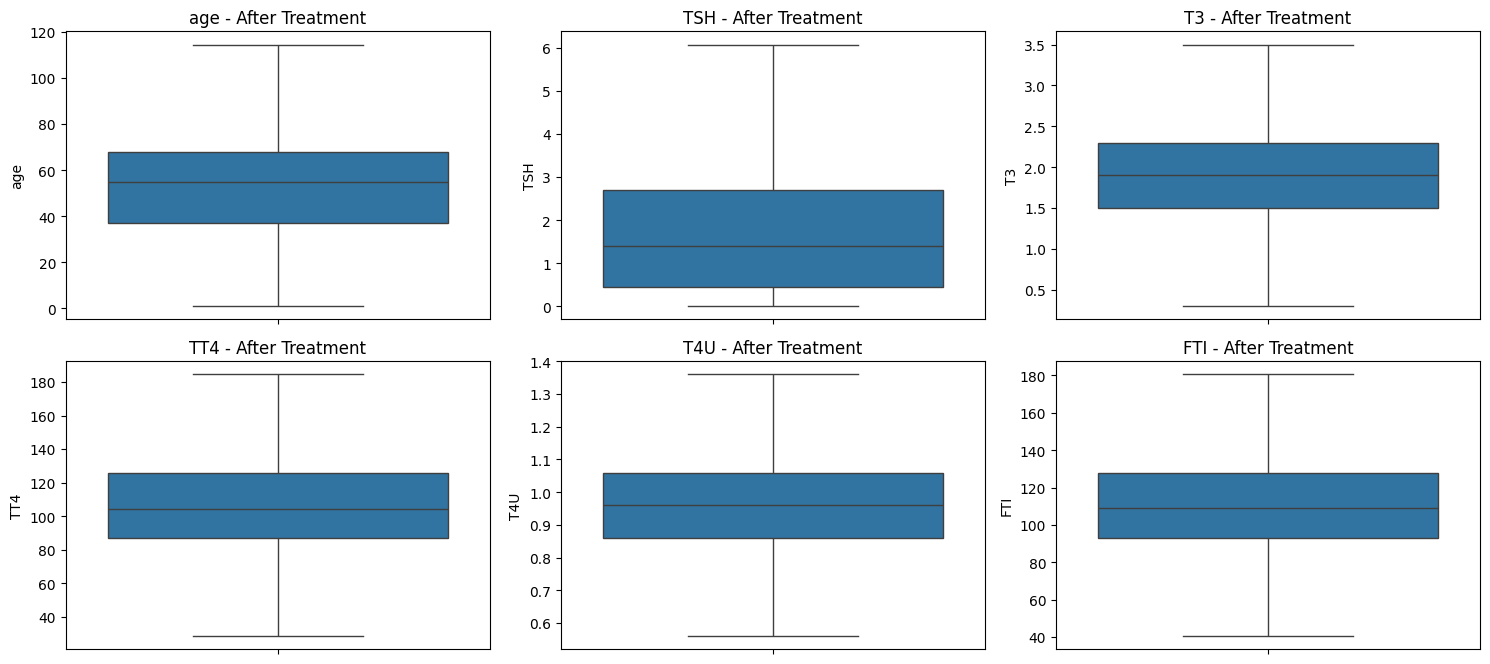

In [51]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(outlier_cols, 1):

    plt.subplot(3, 3, i)

    sns.boxplot(y=X_train[col])

    plt.title(f'{col} - After Treatment')

plt.tight_layout()
plt.show()

##Compare before-and-after outlier counts

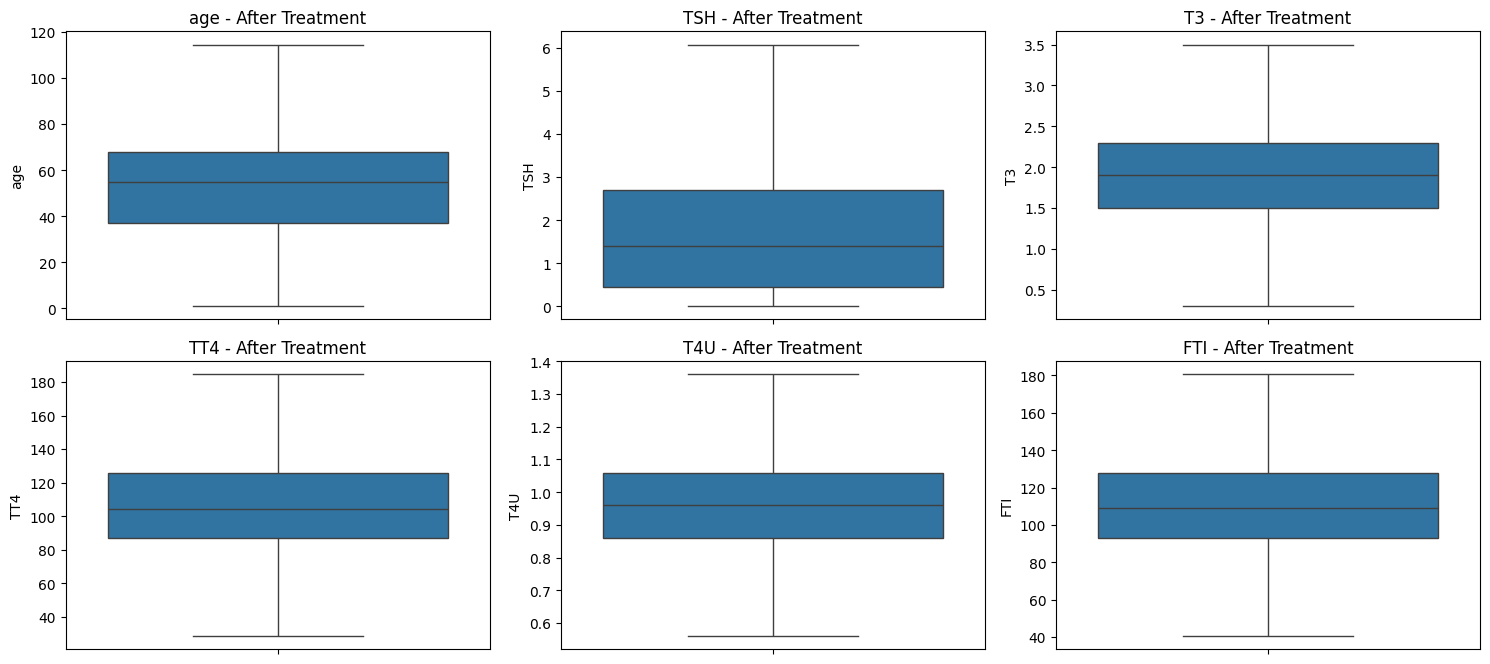

In [52]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(outlier_cols, 1):

    plt.subplot(3, 3, i)

    sns.boxplot(y=X_train[col])

    plt.title(f'{col} - After Treatment')

plt.tight_layout()
plt.show()


In [53]:
comparison = []

for col in outlier_cols:
    lower_bound, upper_bound = outlier_bounds[col]

    # Using X_train_num_imputer which holds the values before outlier capping
    before = (
        (X_train_num_imputer[col] < lower_bound) |
        (X_train_num_imputer[col] > upper_bound)
    ).sum()

    after = (
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    ).sum()

    comparison.append({
        'Column': col,
        'Before Treatment': before,
        'After Treatment': after
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

,Column,Before Treatment,After Treatment
0,age,4,0
1,TSH,703,0
2,T3,298,0
3,TT4,331,0
4,T4U,354,0
5,FTI,397,0


In [54]:
X_train_original = X_train.copy()

Analyse numerical feature distributions using histograms and KDE

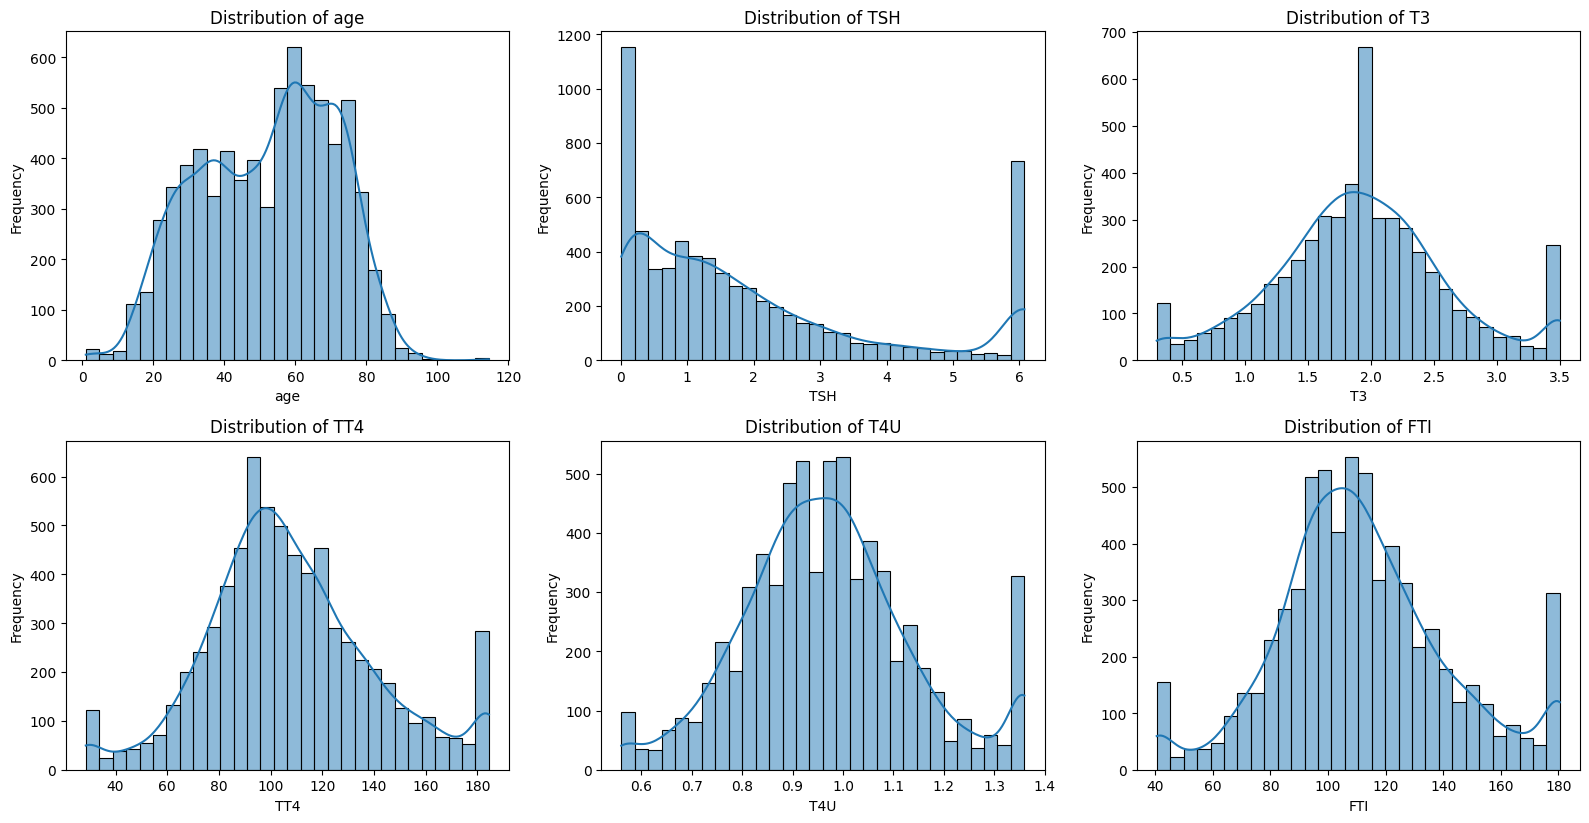

In [55]:
plt.figure(figsize=(16, 12))

for i, col in enumerate(outlier_cols, 1):

    plt.subplot(3, 3, i)

    sns.histplot(
        X_train[col].dropna(),
        bins=30,
        kde=True
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


Check skewness of numerical columns

In [56]:
skewness_results = []

for col in outlier_cols:

    skew_value = X_train[col].skew()

    if skew_value > 1:
        interpretation = "Highly Right Skewed"

    elif skew_value < -1:
        interpretation = "Highly Left Skewed"

    else:
        interpretation = "Approximately Symmetrical / Moderately Skewed"

    skewness_results.append({
        'Column': col,
        'Skewness': skew_value,
        'Distribution': interpretation
    })

skewness_df = pd.DataFrame(skewness_results)

display(skewness_df.round(3))


,Column,Skewness,Distribution
0,age,-0.202,Approximately Symmetrical / Moderately Skewed
1,TSH,1.096,Highly Right Skewed
2,T3,0.133,Approximately Symmetrical / Moderately Skewed
3,TT4,0.312,Approximately Symmetrical / Moderately Skewed
4,T4U,0.266,Approximately Symmetrical / Moderately Skewed
5,FTI,0.277,Approximately Symmetrical / Moderately Skewed


In [57]:
from sklearn.preprocessing import PowerTransformer
skewed_cols = [
    col for col in outlier_cols
    if abs(X_train_num_imputer[col].skew()) > 1
]

print("Highly skewed columns:", skewed_cols)

if len(skewed_cols) > 0:

    power_transformer = PowerTransformer(
        method='yeo-johnson',
        standardize=False
    )

    X_train_num_imputer.loc[:, skewed_cols] = (
        power_transformer.fit_transform(
            X_train_num_imputer[skewed_cols]
        )
    )

    X_test_num_imputer.loc[:, skewed_cols] = (
        power_transformer.transform(
            X_test_num_imputer[skewed_cols]
        )
    )

    print("Power transformation applied successfully!")

else:
    print("No highly skewed columns require transformation.")


Highly skewed columns: ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']
Power transformation applied successfully!


Final distribution plots after transformation

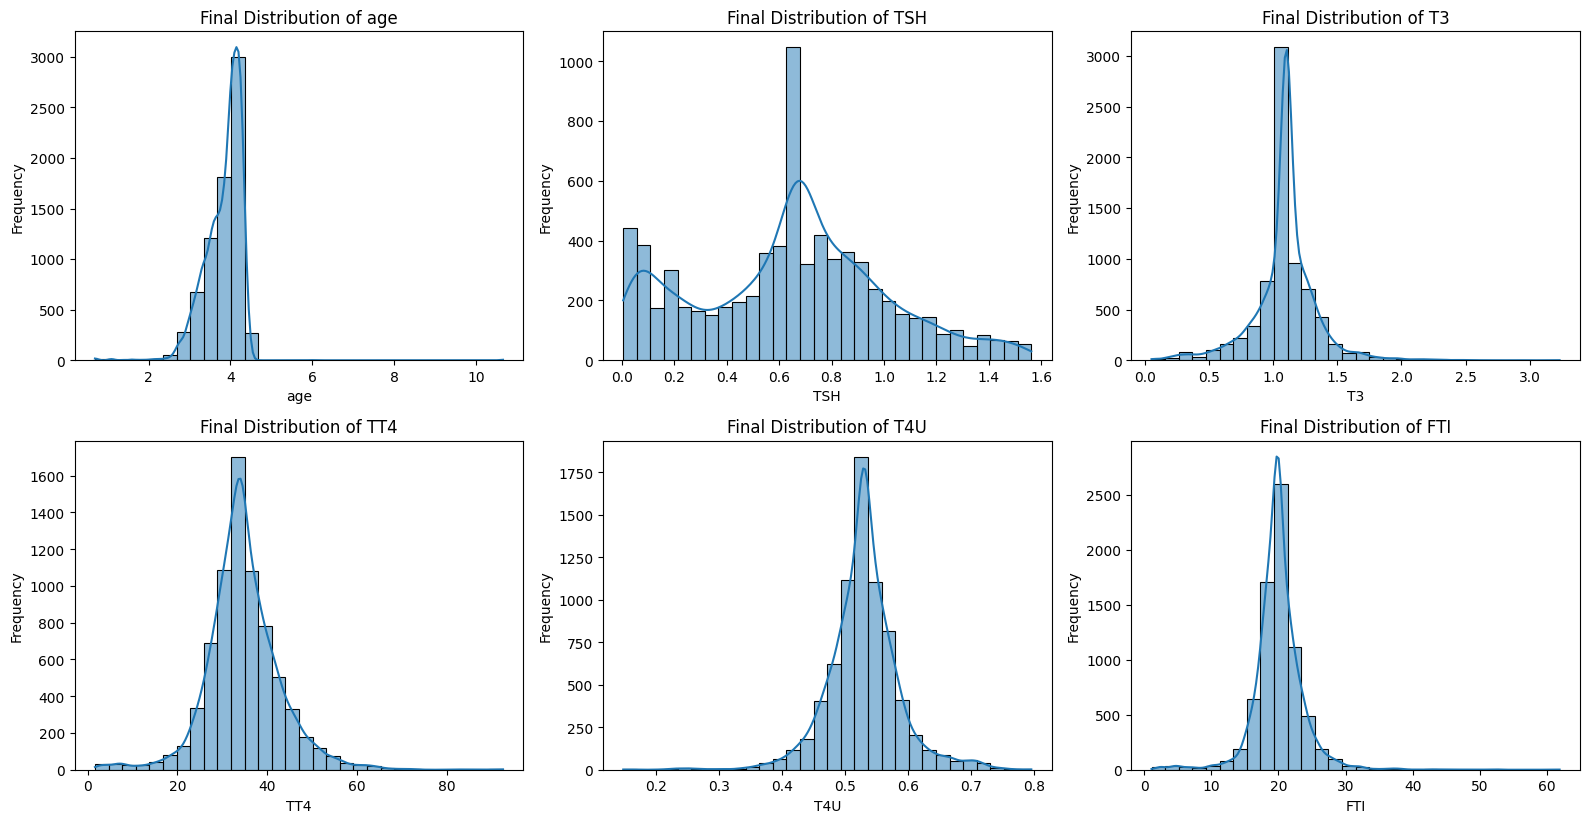

In [58]:
plt.figure(figsize=(16, 12))

for i, col in enumerate(outlier_cols, 1):

    plt.subplot(3, 3, i)

    sns.histplot(
        X_train_num_imputer[col],
        bins=30,
        kde=True
    )

    plt.title(f'Final Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


Final skewness comparison

In [59]:
final_skewness = []

for col in outlier_cols:

    before = X_train[col].skew()
    after = X_train_num_imputer[col].skew()

    final_skewness.append({
        'Column': col,
        'Before Transformation': before,
        'After Transformation': after
    })

final_skewness_df = pd.DataFrame(final_skewness)

display(final_skewness_df.round(3))


,Column,Before Transformation,After Transformation
0,age,-0.202,-0.028
1,TSH,1.096,0.097
2,T3,0.133,0.025
3,TT4,0.312,0.266
4,T4U,0.266,-0.079
5,FTI,0.277,0.591


# Encoding and Feature scaling  - Nezrin N

Checking unique values in each categorical column

In [60]:
for col in cat_cols:
  print(f"{col}====>{df[col].unique()}")

sex====>['F' 'M' nan]
on_thyroxine====>['f' 't']
query_on_thyroxine====>['f' 't']
on_antithyroid_meds====>['f' 't']
sick====>['f' 't']
pregnant====>['f' 't']
thyroid_surgery====>['f' 't']
I131_treatment====>['f' 't']
query_hypothyroid====>['t' 'f']
query_hyperthyroid====>['f' 't']
lithium====>['f' 't']
goitre====>['f' 't']
tumor====>['f' 't']
hypopituitary====>['f' 't']
psych====>['f' 't']
TSH_measured====>['t' 'f']
T3_measured====>['f' 't']
TT4_measured====>['f' 't']
T4U_measured====>['f' 't']
FTI_measured====>['f' 't']
TBG_measured====>['f' 't']
referral_source====>['other' 'SVI' 'SVHC' 'STMW' 'SVHD' 'WEST']


Missing value handling in
categorical columns

In [61]:
cat_imputer = SimpleImputer(strategy='most_frequent')


X_train_cat = pd.DataFrame(cat_imputer.fit_transform(X_train[cat_cols]), columns=cat_cols, index=X_train.index)
X_test_cat = pd.DataFrame(cat_imputer.transform(X_test[cat_cols]), columns=cat_cols, index=X_test.index)


In [62]:
print("\nMissing after imputation -> train:",X_train_cat.isna().sum().sum(), "| test:", X_test_cat.isna().sum().sum())


Missing after imputation -> train: 0 | test: 0


One Hot Encoding

In [63]:
onehot_cols = cat_cols
print("One-hot columns:", onehot_cols)

One-hot columns: Index(['sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_meds',
       'sick', 'pregnant', 'thyroid_surgery', 'I131_treatment',
       'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor',
       'hypopituitary', 'psych', 'TSH_measured', 'T3_measured', 'TT4_measured',
       'T4U_measured', 'FTI_measured', 'TBG_measured', 'referral_source'],
      dtype='object')


In [64]:
encoder = OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False)

encoded_data = encoder.fit_transform(X_train_cat[onehot_cols])
encoded_test = encoder.transform(X_test_cat[onehot_cols])

In [65]:
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(onehot_cols),
    index=X_train.index
).astype(int)

encoded_test_df = pd.DataFrame(
    encoded_test,
    columns=encoder.get_feature_names_out(onehot_cols),
    index=X_test.index
).astype(int)


In [66]:
print(encoded_df.shape, encoded_test_df.shape)
encoded_df.head()

(7333, 27) (1834, 27)


,sex_M,on_thyroxine_t,query_on_thyroxine_t,on_antithyroid_meds_t,sick_t,pregnant_t,thyroid_surgery_t,I131_treatment_t,query_hypothyroid_t,query_hyperthyroid_t,lithium_t,goitre_t,tumor_t,hypopituitary_t,psych_t,TSH_measured_t,T3_measured_t,TT4_measured_t,T4U_measured_t,FTI_measured_t,TBG_measured_t,referral_source_STMW,referral_source_SVHC,referral_source_SVHD,referral_source_SVI,referral_source_WEST,referral_source_other
5734,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1
1223,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1
5318,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1
5388,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,1,0,0,0,0,0
5650,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1


Label encoding (target variable)

In [67]:
label_encoder = LabelEncoder()

y_train_encoded = pd.DataFrame(
    label_encoder.fit_transform(y_train),
    columns=['target'],
    index=y_train.index
)
y_test_encoded = pd.DataFrame(
    label_encoder.transform(y_test),
    columns=['target'],
    index=y_test.index
)


Feature Scaling

Numerical columns

In [68]:
num_train = X_train_num_imputer.drop(columns=['patient_id'])
num_test = X_test_num_imputer.drop(columns=['patient_id'])

num_scale_cols = num_train.columns.tolist()
print("Columns to scale:", num_scale_cols)

Columns to scale: ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']


StandardScaler

In [69]:
scaler = StandardScaler()

X_train_num_scale = scaler.fit_transform(num_train)
X_test_num_scale = scaler.transform(num_test)

X_train_num_df = pd.DataFrame(X_train_num_scale, columns=num_scale_cols, index=num_train.index)
X_test_num_df = pd.DataFrame(X_test_num_scale, columns=num_scale_cols, index=num_test.index)

##Class Imbalance and Feature Selection - Soju Jacob Sony

Combine num_col and cat_col

In [70]:
#concat num_col and cat_col
X_train_final=pd.concat([X_train_num_df,encoded_df],axis=1)
X_test_final=pd.concat([X_test_num_df,encoded_test_df],axis=1)

In [71]:
X_train_final

,age,TSH,T3,TT4,T4U,FTI,sex_M,on_thyroxine_t,query_on_thyroxine_t,on_antithyroid_meds_t,sick_t,pregnant_t,thyroid_surgery_t,I131_treatment_t,query_hypothyroid_t,query_hyperthyroid_t,lithium_t,goitre_t,tumor_t,hypopituitary_t,psych_t,TSH_measured_t,T3_measured_t,TT4_measured_t,T4U_measured_t,FTI_measured_t,TBG_measured_t,referral_source_STMW,referral_source_SVHC,referral_source_SVHD,referral_source_SVI,referral_source_WEST,referral_source_other
5734,-0.043276,0.779234,0.036011,0.454132,0.319091,0.262210,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1
1223,-1.264293,1.262524,0.036011,0.480906,0.319091,0.288279,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1
5318,0.532051,-0.461021,0.036011,-0.040127,-0.624669,0.365871,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1
5388,-1.040322,-0.137821,2.223758,1.429539,3.153404,-0.486162,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,1,0,0,0,0,0
5650,0.955885,1.039442,0.036011,-1.547727,-1.188085,-1.110877,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5144,-1.344561,0.083815,0.457968,0.182548,0.619895,-0.142180,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,1,1,1,0,1,0,0,0,0,0
3066,-1.040322,0.083815,0.036011,-0.068325,0.002305,-0.031766,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1
5901,-0.429644,1.437535,0.036011,-0.012012,-0.107076,0.103548,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1
4492,0.393371,-0.650894,0.181033,1.180535,0.471411,0.861597,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,0,0,0,0,0,1


In [72]:
X_test_final

,age,TSH,T3,TT4,T4U,FTI,sex_M,on_thyroxine_t,query_on_thyroxine_t,on_antithyroid_meds_t,sick_t,pregnant_t,thyroid_surgery_t,I131_treatment_t,query_hypothyroid_t,query_hyperthyroid_t,lithium_t,goitre_t,tumor_t,hypopituitary_t,psych_t,TSH_measured_t,T3_measured_t,TT4_measured_t,T4U_measured_t,FTI_measured_t,TBG_measured_t,referral_source_STMW,referral_source_SVHC,referral_source_SVHD,referral_source_SVI,referral_source_WEST,referral_source_other
5396,-0.538435,0.147947,-0.113776,0.071845,0.056269,0.049772,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,0,0,0,0,0,1
7778,1.237575,0.860882,-1.329366,-1.279859,-2.721419,0.156872,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,0,0,0,1,0,0
5445,-0.133422,0.083815,0.036011,-0.153429,-0.052141,-0.114390,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1
2075,-0.483337,-1.297974,0.181033,-0.834642,-0.624669,-0.515765,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,0,0,0,1,0,0
7133,-2.127804,0.749764,0.844362,0.099637,-0.274882,0.288279,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4442,-2.516914,0.933753,-1.134284,-0.096608,-0.447344,0.209756,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,0,0,0,1,0,0
2171,0.843273,-1.640402,-1.329366,0.043973,-1.876072,1.347547,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,0,0,0,1,0,0
2373,-1.428001,-1.404014,1.085067,0.264780,-0.807077,0.837631,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,1,1,0,0,0,0,0,0,1
8444,-1.186965,0.015180,-0.113776,1.404860,0.812167,0.837631,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,0,0,0,0,0,1


###Class Imabalance

Before Imbalance

In [73]:
y_train.value_counts()

,count
target,
-,5416
K,349
G,287
I,277
F,186
R,157
A,117
L,92
M,89


###Class Imbalance using SMOTE

In [74]:
smote=SMOTE(k_neighbors=1, random_state=42)
X_train_imbalance,y_train_imbalance=smote.fit_resample(X_train_final,y_train_encoded)

After Class imbalance

In [75]:
y_train_imbalance.value_counts()

,count
target,
0,5416
1,5416
2,5416
3,5416
4,5416
5,5416
6,5416
7,5416
8,5416


###Heatmap Correleation

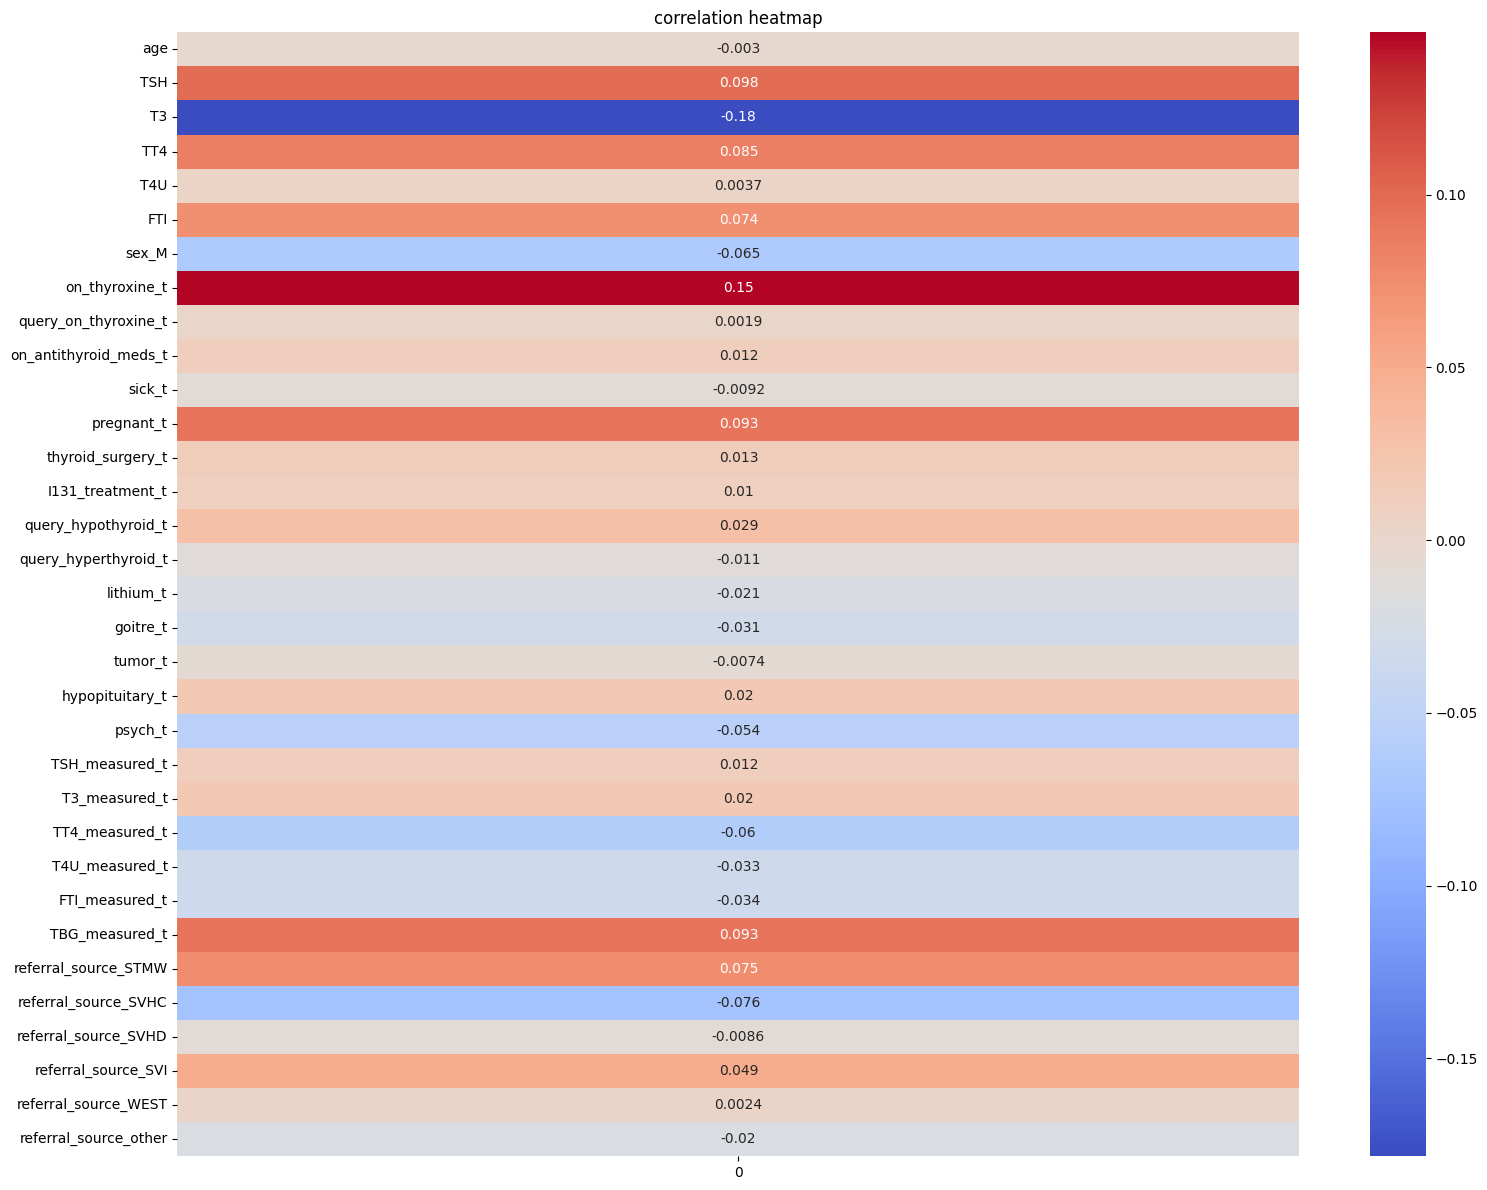

In [76]:
plt.figure(figsize=(16,12))
corr=X_train_final.corrwith(
    y_train_encoded.iloc[:,0],
).to_frame()
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.title('correlation heatmap')
plt.tight_layout()
plt.show()

###Feature Selection

In [77]:
selected_features = [
    'T3_measured_t',
    'on_antithyroid_meds_t',
    'referral_source_SVI',
    'I131_treatment_t',
    'sex_M',
    'goitre_t',
    'referral_source_SVHD',
    'referral_source_SVHC',
    'tumor_t',
    'lithium_t'
]

In [78]:
X_train_selected=X_train_imbalance[selected_features]
X_test_selected=X_test_final[selected_features]

Selected X_train Columns

In [79]:
X_train_selected

,T3_measured_t,on_antithyroid_meds_t,referral_source_SVI,I131_treatment_t,sex_M,goitre_t,referral_source_SVHD,referral_source_SVHC,tumor_t,lithium_t
0,0,0,0,0,1,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
146227,0,0,0,0,0,0,0,0,0,0
146228,0,0,0,0,0,0,0,0,0,0
146229,0,0,0,0,0,0,0,0,1,0
146230,0,0,0,0,0,0,0,0,0,0


Selected X_test Columns

In [80]:
X_test_selected

,T3_measured_t,on_antithyroid_meds_t,referral_source_SVI,I131_treatment_t,sex_M,goitre_t,referral_source_SVHD,referral_source_SVHC,tumor_t,lithium_t
5396,1,0,0,0,1,0,0,0,0,0
7778,1,0,1,0,0,0,0,0,0,0
5445,0,0,0,0,1,0,0,0,0,0
2075,1,0,1,0,1,0,0,0,0,0
7133,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
4442,1,0,1,0,0,0,0,0,0,0
2171,1,0,1,0,1,0,0,0,0,0
2373,1,0,0,0,1,0,0,0,0,0
8444,1,0,0,0,0,0,0,0,0,0


Graph analysis

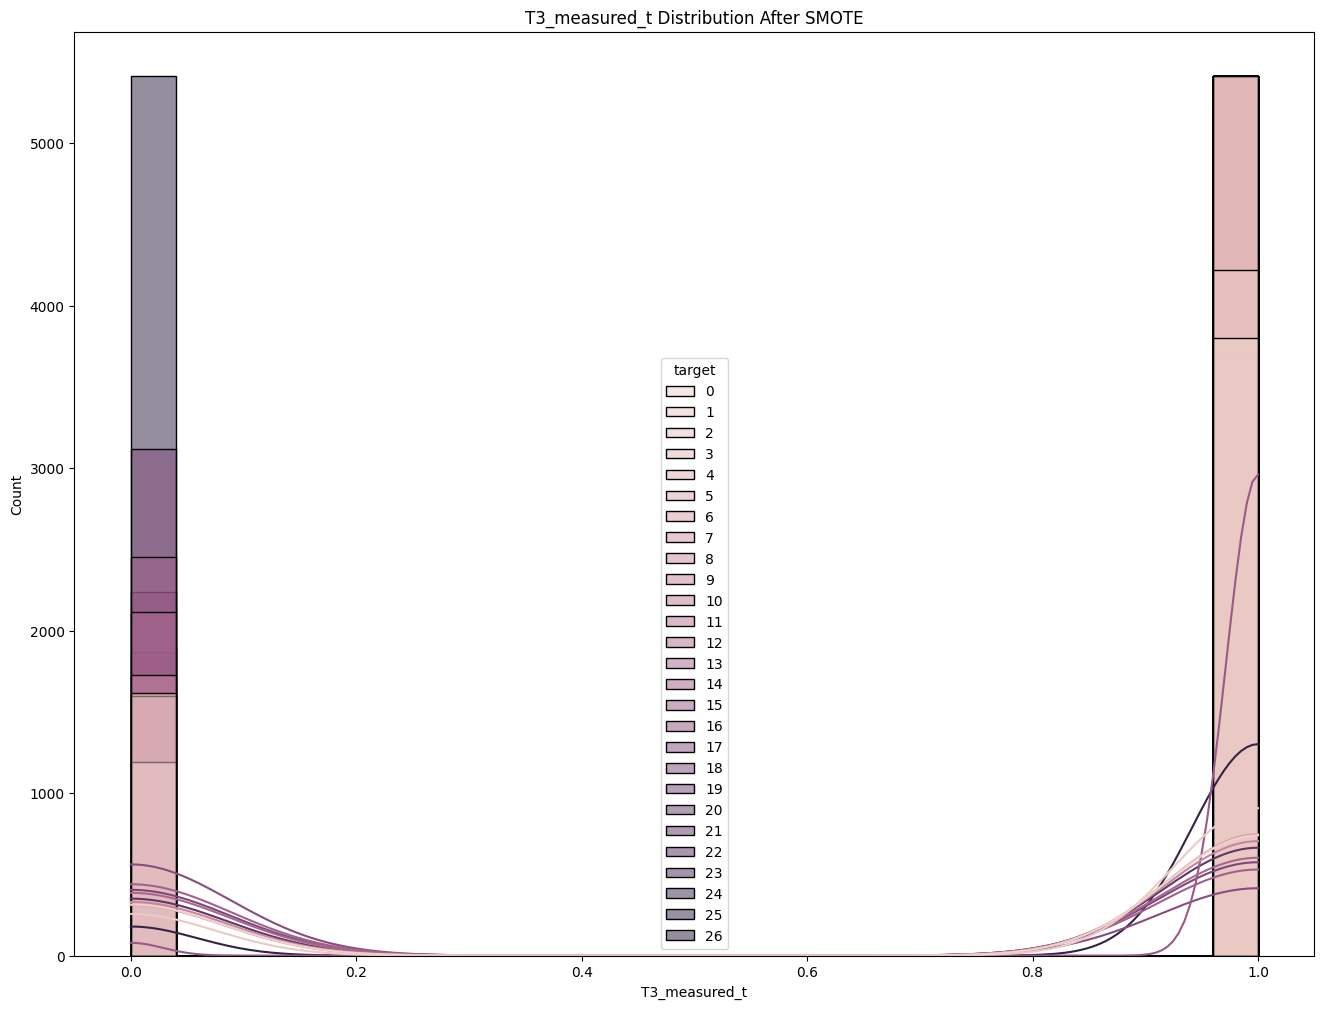

In [81]:
# Combine X_train_imbalance and y_train_imbalance
df_copy = X_train_imbalance.copy()

df_copy['target'] = y_train_imbalance

plt.figure(figsize=(16, 12))

sns.histplot(
    data=df_copy,
    x='T3_measured_t',
    hue='target',
    bins=25,
    kde=True
)

plt.title('T3_measured_t Distribution After SMOTE')
plt.xlabel('T3_measured_t')
plt.ylabel('Count')

plt.show()

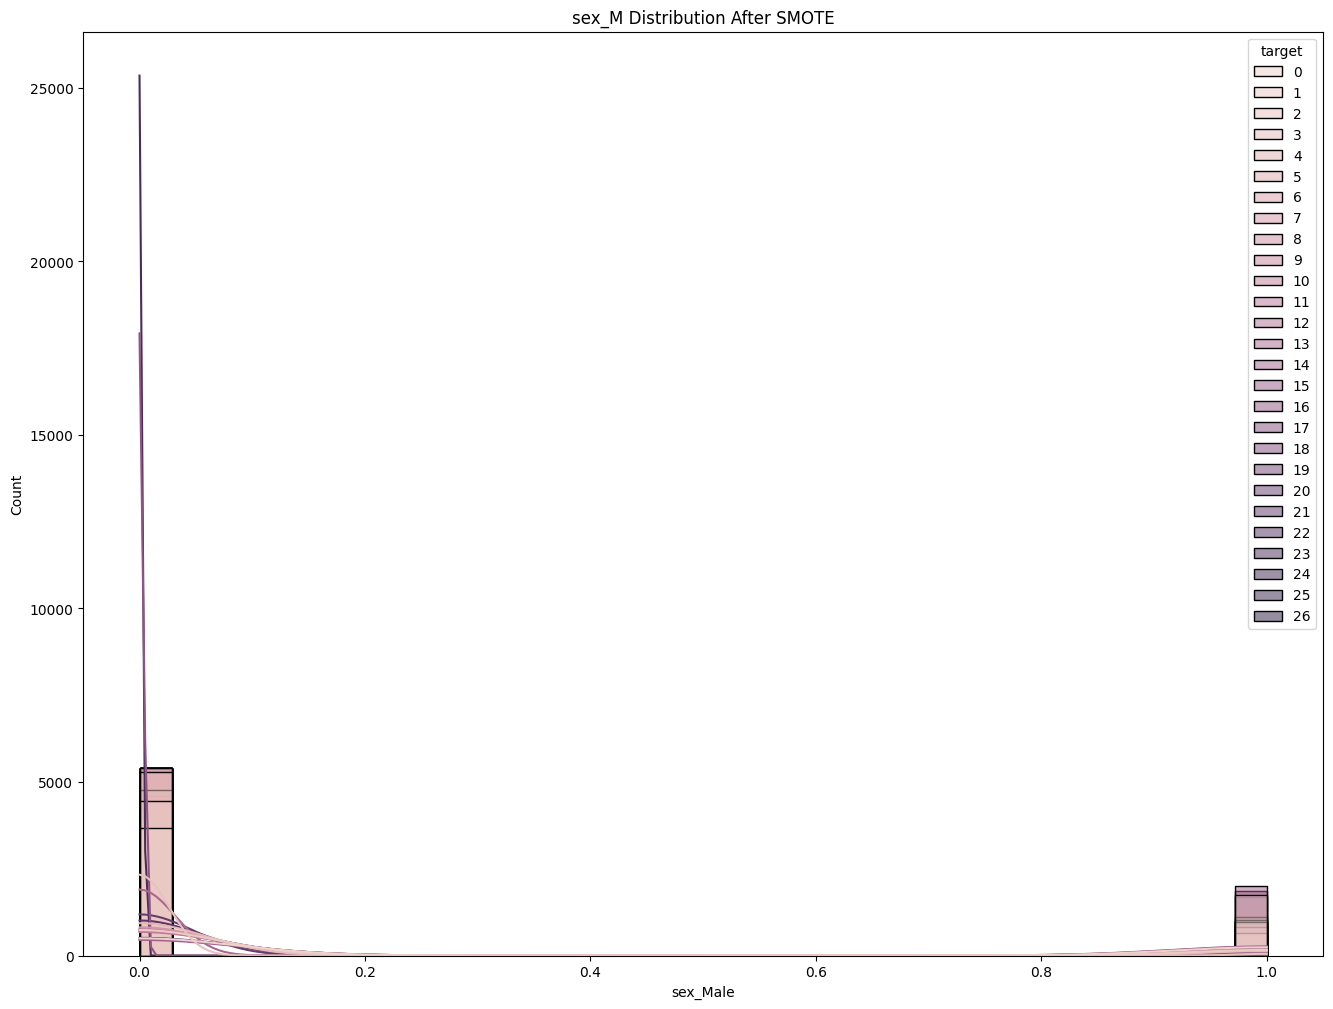

In [82]:
# Combine X_train_imbalance and y_train_imbalance
df_copy = X_train_imbalance.copy()

df_copy['target'] = y_train_imbalance

plt.figure(figsize=(16, 12))

sns.histplot(
    data=df_copy,
    x='sex_M',
    hue='target',
    bins=35,
    kde=True
)

plt.title('sex_M Distribution After SMOTE')
plt.xlabel('sex_Male')
plt.ylabel('Count')

plt.show()